**IMPORT LIBRARIES**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google import genai

**A.LOAD AND UNDERSTAND DATASET**

In [5]:
df = pd.read_csv('/content/food_delivery_dataset.csv')
print("--- 1. LOADING DATASET ---")
print(df)



--- 1. LOADING DATASET ---
           ID Delivery_person_ID  Delivery_person_Age  \
0      0xcdcd      DEHRES17DEL01                 36.0   
1      0xd987      KOCRES16DEL01                 21.0   
2      0x2784     PUNERES13DEL03                 23.0   
3      0xc8b6     LUDHRES15DEL02                 34.0   
4      0xdb64      KNPRES14DEL02                 24.0   
...       ...                ...                  ...   
38959  0x1178   RANCHIRES16DEL01                 35.0   
38960  0x7c09      JAPRES04DEL01                 30.0   
38961  0x4f8d     CHENRES08DEL03                 30.0   
38962  0x5eee    COIMBRES11DEL01                 20.0   
38963  0x5fb2   RANCHIRES09DEL02                 23.0   

       Delivery_person_Ratings  Restaurant_latitude  Restaurant_longitude  \
0                          4.2            30.327968             78.046106   
1                          4.7            10.003064             76.307589   
2                          4.7            18.562450      

**ROWS AND COLUMNS**

In [6]:
print("\n[Shape]:", df.shape)


[Shape]: (38964, 22)


**COLUMN NAMES**

In [7]:
print("\n[Columns]:\n", df.columns.tolist())


[Columns]:
 ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)', 'distance_km', 'delivery_speed']


**DATA TYPES**

In [8]:
print(df.dtypes)

ID                              object
Delivery_person_ID              object
Delivery_person_Age            float64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                      object
Time_Orderd                     object
Time_Order_picked               object
Weather_conditions              object
Road_traffic_density            object
Vehicle_condition                int64
Type_of_order                   object
Type_of_vehicle                 object
multiple_deliveries            float64
Festival                        object
City                            object
Time_taken (min)                 int64
distance_km                    float64
delivery_speed                  object
dtype: object


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38964 entries, 0 to 38963
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           38964 non-null  object 
 1   Delivery_person_ID           38964 non-null  object 
 2   Delivery_person_Age          37945 non-null  float64
 3   Delivery_person_Ratings      37909 non-null  float64
 4   Restaurant_latitude          38964 non-null  float64
 5   Restaurant_longitude         38964 non-null  float64
 6   Delivery_location_latitude   38964 non-null  float64
 7   Delivery_location_longitude  38964 non-null  float64
 8   Order_Date                   38964 non-null  object 
 9   Time_Orderd                  38129 non-null  object 
 10  Time_Order_picked            38964 non-null  object 
 11  Weather_conditions           38964 non-null  object 
 12  Road_traffic_density         38964 non-null  object 
 13  Vehicle_conditio

**DUPLICATE VALUES**

In [11]:
# 1. Check the total count of duplicate records
duplicate_count = df.duplicated().sum()
print(f"Total Duplicate Records: {duplicate_count}")

# 2. Display the duplicate records (to inspect which specific rows are repeated)
duplicate_rows = df[df.duplicated()]
print("\nDuplicate Rows:")
print(duplicate_rows)

# 3. Remove duplicate records
df_clean = df.drop_duplicates()
print(f"\nRows after removing duplicates: {len(df_clean)}")

Total Duplicate Records: 0

Duplicate Rows:
Empty DataFrame
Columns: [ID, Delivery_person_ID, Delivery_person_Age, Delivery_person_Ratings, Restaurant_latitude, Restaurant_longitude, Delivery_location_latitude, Delivery_location_longitude, Order_Date, Time_Orderd, Time_Order_picked, Weather_conditions, Road_traffic_density, Vehicle_condition, Type_of_order, Type_of_vehicle, multiple_deliveries, Festival, City, Time_taken (min), distance_km, delivery_speed]
Index: []

[0 rows x 22 columns]

Rows after removing duplicates: 38964


**MISSING VALUES**

In [12]:
# 1. Check the total count and percentage of missing values per column
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percent.round(2)
})

print("Missing Values Per Column:")
print(missing_summary[missing_summary['Missing Count'] > 0])


# 2. Display rows containing missing values (to inspect incomplete records)
missing_rows = df[df.isnull().any(axis=1)]
print("\nRows with Missing Values:")
print(missing_rows)


# 3. Handle and clean missing values
# Impute numeric columns with median/mean
df['Delivery_person_Age'] = df['Delivery_person_Age'].fillna(df['Delivery_person_Age'].median())
df['Delivery_person_Ratings'] = df['Delivery_person_Ratings'].fillna(df['Delivery_person_Ratings'].mean())

# Impute timestamp column using backfill
df['Time_Orderd'] = df['Time_Orderd'].bfill()

print(f"\nTotal remaining missing values after cleaning: {df.isnull().sum().sum()}")

Missing Values Per Column:
                         Missing Count  Percentage (%)
Delivery_person_Age               1019            2.62
Delivery_person_Ratings           1055            2.71
Time_Orderd                        835            2.14

Rows with Missing Values:
           ID Delivery_person_ID  Delivery_person_Age  \
31      0x4f0      MUMRES17DEL02                  NaN   
100    0xd0e5      KOLRES17DEL03                 23.0   
141    0x1b58      JAPRES03DEL01                  NaN   
207     0xe76     CHENRES06DEL02                  NaN   
243     0x6a7   RANCHIRES08DEL01                  NaN   
...       ...                ...                  ...   
38777   0xac6      MYSRES16DEL01                  NaN   
38803  0xc7ed      KNPRES20DEL03                  NaN   
38893  0x426b      HYDRES06DEL01                  NaN   
38908  0x1ed1      JAPRES18DEL01                  NaN   
38943  0x1163      SURRES06DEL02                  NaN   

       Delivery_person_Ratings  Restauran

**B.CLEAN THE DATA**

In [13]:
# ---------------------------------------------------------
# 1. IDENTIFY PROBLEMS (Missing, Duplicates, Data Types)
# ---------------------------------------------------------
print("--- BEFORE CLEANING ---")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")
print("Missing Values Per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# ---------------------------------------------------------
# 2. APPLY CLEANING METHODS
# ---------------------------------------------------------

# A. Remove Duplicates (if any exist)
df.drop_duplicates(inplace=True)

# B. Handle Missing Values
# Impute Age with median to handle extreme values
df['Delivery_person_Age'] = df['Delivery_person_Age'].fillna(df['Delivery_person_Age'].median())

# Impute Ratings with mean to maintain average performance distribution
df['Delivery_person_Ratings'] = df['Delivery_person_Ratings'].fillna(df['Delivery_person_Ratings'].mean())

# Impute Time_Orderd using backfill method
df['Time_Orderd'] = df['Time_Orderd'].bfill()

# C. Fix Incorrect Data Types & Format Cleanups
# Convert numerical columns from object/float to appropriate types
df['Delivery_person_Age'] = df['Delivery_person_Age'].astype(int)
df['Delivery_person_Ratings'] = df['Delivery_person_Ratings'].round(2)

# Extract numeric value from 'Time_taken (min)' if formatted as string (e.g., '(min) 24' -> 24)
if df['Time_taken (min)'].dtype == 'object':
    df['Time_taken (min)'] = df['Time_taken (min)'].str.extract(r'(\d+)').astype(int)

# ---------------------------------------------------------
# 3. VERIFY CLEANING
# ---------------------------------------------------------
print("\n--- AFTER CLEANING ---")
print(f"Total Remaining Missing Values: {df.isnull().sum().sum()}")
print(f"Total Remaining Duplicate Rows: {df.duplicated().sum()}")
print("Data Types Updated:")
print(df[['Delivery_person_Age', 'Delivery_person_Ratings', 'Time_taken (min)']].dtypes)

--- BEFORE CLEANING ---
Total Duplicate Rows: 0
Missing Values Per Column:
Series([], dtype: int64)

--- AFTER CLEANING ---
Total Remaining Missing Values: 0
Total Remaining Duplicate Rows: 0
Data Types Updated:
Delivery_person_Age          int64
Delivery_person_Ratings    float64
Time_taken (min)             int64
dtype: object


**C.BASIC ANALYSIS**

In [14]:
# Calculate total deliveries
total_deliveries = len(df)
print(f"Total Deliveries: {total_deliveries}")

Total Deliveries: 38964


In [15]:
# Calculate delivery time metrics
avg_time = df['Time_taken (min)'].mean()
min_time = df['Time_taken (min)'].min()
max_time = df['Time_taken (min)'].max()

print(f"Average Delivery Time: {avg_time:.2f} minutes")
print(f"Minimum Delivery Time: {min_time} minutes")
print(f"Maximum Delivery Time: {max_time} minutes")

Average Delivery Time: 26.58 minutes
Minimum Delivery Time: 10 minutes
Maximum Delivery Time: 54 minutes


In [16]:
# 1. Haversine distance calculate karna
lat1, lon1 = np.radians(df['Restaurant_latitude']), np.radians(df['Restaurant_longitude'])
lat2, lon2 = np.radians(df['Delivery_location_latitude']), np.radians(df['Delivery_location_longitude'])

dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
df['distance_km'] = 2 * 6371 * np.arcsin(np.sqrt(a))

# 2. Speed (km/h) calculate karna
df['delivery_speed_kmh'] = df['distance_km'] / (df['Time_taken (min)'] / 60)

# 3. Output print karna
print(f"Average Delivery Distance: {df['distance_km'].mean():.2f} km")
print(f"Average Delivery Speed: {df['delivery_speed_kmh'].replace(np.inf, np.nan).mean():.2f} km/h")

Average Delivery Distance: 9.77 km
Average Delivery Speed: 23.59 km/h


In [17]:
# Calculate average rating and age
avg_rating = df['Delivery_person_Ratings'].mean()
avg_age = df['Delivery_person_Age'].mean()

print(f"Average Delivery Person Rating: {avg_rating:.2f}")
print(f"Average Delivery Person Age:    {avg_age:.1f} years")

Average Delivery Person Rating: 4.63
Average Delivery Person Age:    29.6 years


**D. Answer the 3 Competition Questions**

In [18]:
# Q1 – Traffic Impact: Which road traffic condition has the highest average delivery time?
# Group by road traffic density and calculate average delivery time
traffic_impact = df.groupby('Road_traffic_density')['Time_taken (min)'].mean().sort_values(ascending=False)

# Display all traffic density averages
print("Average Delivery Time by Traffic Condition:")
print(traffic_impact.round(2))

# Extract highest condition
highest_traffic = traffic_impact.index[0]
highest_time = traffic_impact.iloc[0]

print(f"\nAnswer: '{highest_traffic}' traffic density has the highest average delivery time ({highest_time:.2f} mins).")

Average Delivery Time by Traffic Condition:
Road_traffic_density
Jam       31.44
High      27.41
Medium    26.93
Low       21.50
Name: Time_taken (min), dtype: float64

Answer: 'Jam' traffic density has the highest average delivery time (31.44 mins).


In [19]:
# Q2 – Distance Impact: How does delivery distance affect delivery time? Support your conclusion with data.
# 1. Calculate Correlation between Distance and Time
correlation = df['distance_km'].corr(df['Time_taken (min)'])

# 2. Group distance into ranges to see average time for each bracket
df['distance_range'] = pd.cut(df['distance_km'], bins=[0, 5, 10, 15, 20, 100], labels=['0-5 km', '5-10 km', '10-15 km', '15-20 km', '20+ km'])
distance_grouped = df.groupby('distance_range')['Time_taken (min)'].mean()

# Display Results
print("=========================================")
print(f"Correlation Coefficient: {correlation:.2f}")
print("=========================================")
print("\nAverage Delivery Time by Distance Range:")
print(distance_grouped.round(2))


Correlation Coefficient: 0.32

Average Delivery Time by Distance Range:
distance_range
0-5 km      22.42
5-10 km     24.64
10-15 km    30.09
15-20 km    30.07
20+ km      30.08
Name: Time_taken (min), dtype: float64


/tmp/ipykernel_3459/3865602090.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  distance_grouped = df.groupby('distance_range')['Time_taken (min)'].mean()


In [22]:
# Q3 – Combined Conditions: Which combination of weather condition and traffic density has the highest average delivery time?
# Group by Weather and Traffic Density to calculate average delivery time
combined_impact = df.groupby(['Weather_conditions', 'Road_traffic_density'])['Time_taken (min)'].mean().reset_index()

# Sort to find the highest average time
combined_impact = combined_impact.sort_values(by='Time_taken (min)', ascending=False)

# Display top 5 highest combinations
print("Top 5 Worst Weather & Traffic Combinations for Delivery Time:")
print(combined_impact.head().to_string(index=False))

# Extract highest combination
worst_combo = combined_impact.iloc[0]
print(f"\nAnswer: '{worst_combo['Weather_conditions']}' weather with '{worst_combo['Road_traffic_density']}' traffic density has the highest average delivery time ({worst_combo['Time_taken (min)']:.2f} mins).")

Top 5 Worst Weather & Traffic Combinations for Delivery Time:
Weather_conditions Road_traffic_density  Time_taken (min)
               Fog                  Jam         36.889454
            Cloudy                  Jam         36.708173
             Windy                  Jam         30.396925
        Sandstorms                  Jam         30.248687
            Stormy                  Jam         30.197835

Answer: 'Fog' weather with 'Jam' traffic density has the highest average delivery time (36.89 mins).


**E. Create Visualizations**

Chart 1: Average delivery time by traffic density (recommended: bar chart).


/tmp/ipykernel_3459/3378228001.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Road_traffic_density', y='Time_taken (min)', data=traffic_df, palette=colors)


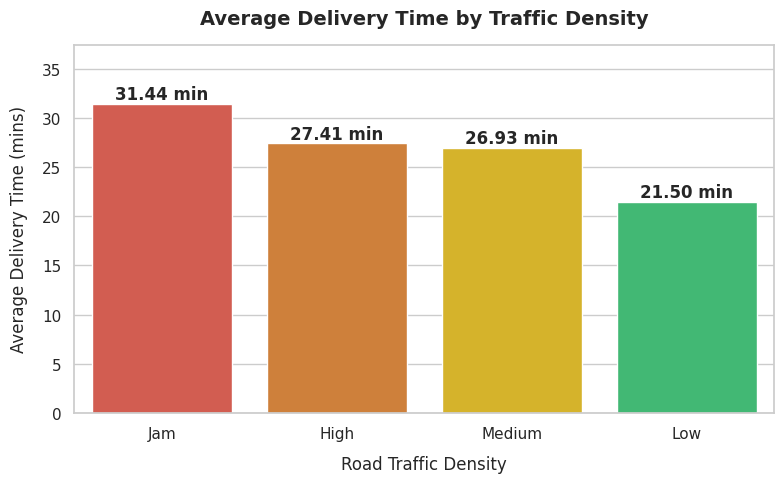

In [23]:
# Set visual style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

# Calculate average delivery time by traffic density
traffic_df = df.groupby('Road_traffic_density')['Time_taken (min)'].mean().reset_index()
traffic_df = traffic_df.sort_values(by='Time_taken (min)', ascending=False)

# Plot bar chart
colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71']
ax = sns.barplot(x='Road_traffic_density', y='Time_taken (min)', data=traffic_df, palette=colors)

# Display exact values on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f} min',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 7),
                textcoords='offset points',
                fontweight='bold')

plt.title('Average Delivery Time by Traffic Density', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Road Traffic Density', fontsize=12, labelpad=10)
plt.ylabel('Average Delivery Time (mins)', fontsize=12, labelpad=10)
plt.ylim(0, max(traffic_df['Time_taken (min)']) + 6)
plt.tight_layout()

# Save image for GitHub README
plt.savefig('traffic_impact_barchart.png', dpi=300)
plt.show()

Chart 2: Delivery distance vs. delivery time (recommended: scatter plot).


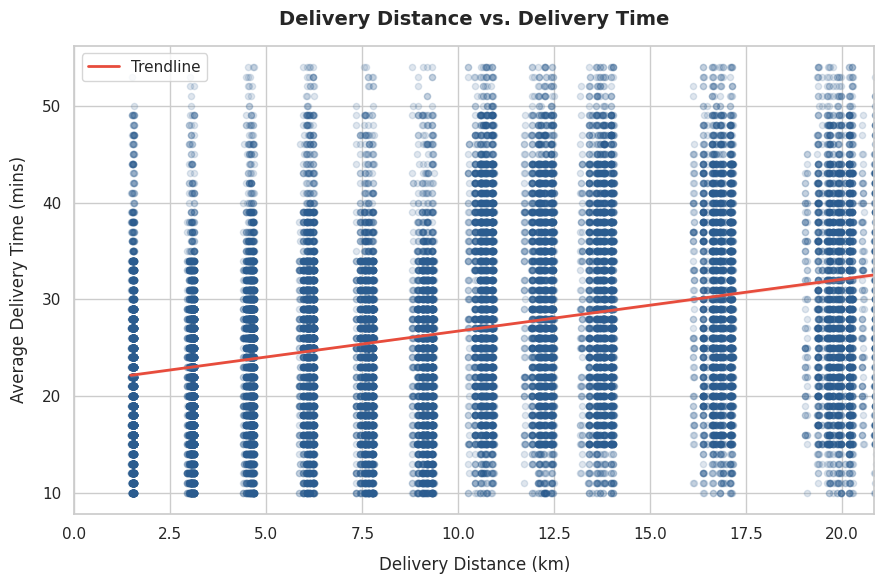

In [24]:
# Set visual style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 6))

# Plot scatter plot with regression trendline
sns.regplot(
    x='distance_km',
    y='Time_taken (min)',
    data=df,
    scatter_kws={'alpha': 0.15, 'color': '#2b5c8f', 's': 20},
    line_kws={'color': '#e74c3c', 'linewidth': 2, 'label': 'Trendline'}
)

plt.title('Delivery Distance vs. Delivery Time', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Delivery Distance (km)', fontsize=12, labelpad=10)
plt.ylabel('Average Delivery Time (mins)', fontsize=12, labelpad=10)
plt.xlim(0, df['distance_km'].quantile(0.99))
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()

# Save image for GitHub README
plt.savefig('distance_vs_time_scatterplot.png', dpi=300)
plt.show()

**G. AI-Powered Explanation**

In [26]:
# Install Gemini library
!pip install -q -U google-genai

import os
from google import genai
from google.colab import userdata

# 1. Safely fetch key from Colab Secrets
api_key = userdata.get('GEMINI_API_KEY')
client = genai.Client(api_key=api_key)

# 2. Calculated results from Pandas analysis (Structured Summary)
analysis_summary = """
Dataset Findings:
- Average delivery time in Jam traffic: 31.44 mins
- Average delivery time in Low traffic: 21.50 mins
- Delay impact due to severe traffic jam: +46.23% increase in time
- Worst combination: Fog weather + Jam traffic (Average time: 36.89 mins)
- Correlation: Distance has a mild positive correlation with delivery time, but traffic density and visibility are stronger bottleneck factors.
"""

# 3. Prompt design for LLM
prompt = f"""
You are a Senior Business Data Analyst. Based on the following data analysis summary,
write a concise, clear 3-paragraph executive explanation for business stakeholders:

{analysis_summary}

Focus on:
1. Core finding and operational bottleneck.
2. Impact on customer experience and fleet management.
3. Strategic recommendations for optimization.
"""

# 4. Make API Call using Gemini 2.5 Flash
response = client.models.generate_content(
    model='gemini-3.6-flash',
    contents=prompt,
)

# Print AI-generated response
print(response.text)

Here is the executive summary based on the data analysis:

Our analysis reveals that traffic congestion and environmental visibility—rather than geographic distance—are the primary drivers of delivery delays. Severe traffic jams create a major operational bottleneck, increasing average delivery times by **46.23%** (rising from 21.50 minutes in low traffic to 31.44 minutes). This bottleneck is significantly exacerbated by poor weather conditions; the combination of heavy fog and jam traffic represents our worst-performing operational scenario, pushing average delivery times to a peak of 36.89 minutes. While distance maintains a mild positive correlation with delivery duration, traffic density and visibility are the statistically dominant factors constraining fleet throughput.

These operational constraints directly threaten customer retention and increase fleet operating costs. The nearly 15-minute variance caused by traffic and weather severely compromises Estimated Time of Arrival (ET